# LightTrap simulation — deep-dive analysis

Interactive PyROOT analysis of a LightTrap Geant4 run (`build/output_apexltsim*.root`).

The two-layer light trap converts LAr VUV (~128 nm) / test-beam UV light into blue
photons that are transported by total internal reflection to edge SiPMs:

1. **First layer** — a thin **pTP** film on a UV-transparent acrylic carrier absorbs
   the incident UV and re-emits in the near-UV/blue.
2. **Second layer** — a **blue-WLS acrylic slab** absorbs those photons and re-emits
   blue, guiding them by TIR to **±y-edge SiPMs** (a Vikuiti ESR foil backs the slab).

This notebook reproduces the efficiency chain (cross-checked against
`analysis/analyze_efficiency.py`) and adds spectra, spatial hit maps,
angular/timing structure, and per-region leak accounting over all 9 TTrees.

> **Backend:** PyROOT + `RDataFrame` (lazy, streamed, multithreaded) so the multi-GB
> file stays memory-safe — no full columns are ever pulled into Python.
> **Kernel:** `Python 3 (ipykernel)` (conda), which provides PyROOT.
> Change **one** variable — `ROOT_FILE` — to analyze a different run.

## 0. Setup & configuration

Imports, batch/multithread config, and the single file knob. `ROOT_FILE` is resolved
against a couple of candidate paths so the notebook runs from either the repo root or
the `analysis/` directory.

In [1]:
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ROOT

ROOT.gROOT.SetBatch(True)          # no popup canvases
ROOT.EnableImplicitMT()            # multithreaded RDataFrame event loops
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3})

# ── single knob: point this at any run file ─────────────────────────────────
_CANDIDATES = [
    "build/output_apexltsim0.root",
    "../build/output_apexltsim0.root",
]
ROOT_FILE = next((p for p in _CANDIDATES if os.path.exists(p)), _CANDIDATES[0])

assert os.path.exists(ROOT_FILE), f"ROOT file not found: {ROOT_FILE}"
_f = ROOT.TFile.Open(ROOT_FILE)
assert _f and not _f.IsZombie(), f"could not open (zombie): {ROOT_FILE}"
_f.Close()
print(f"Analyzing: {ROOT_FILE}  ({os.path.getsize(ROOT_FILE)/1e9:.2f} GB)")
print(f"ROOT {ROOT.__version__}  |  implicit MT threads: {ROOT.GetThreadPoolSize()}")

Analyzing: ../build/output_apexltsim0.root  (3.76 GB)
ROOT 6.40.02  |  implicit MT threads: 14


### Material / process codes and helpers

Mirrors `include/namemap.hh`. `wilson()` is the binomial ratio + 1σ error helper
copied from `analysis/analyze_efficiency.py` (ratios like blue/pTP are not strict
binomials, so their error term is only indicative and flagged by a >100 % value).

In [2]:
# NameMap codes (include/namemap.hh)
MAT = {"pTP": 1, "acrylicMcMaster": 2, "bluewlsacrylic": 3,
       "G4_lAr": 4, "uvTransAcrylic": 5}
PROC = {"Scintillation": 100, "OpWLS": 101}
MAT_PTP, MAT_BLUEWLS = MAT["pTP"], MAT["bluewlsacrylic"]

def wilson(k, n, z=1.0):
    # Binomial ratio p=k/n with symmetric 1-sigma error sqrt(p(1-p)/n).
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    return p, z * math.sqrt(max(p * (1.0 - p), 0.0) / n)

def pct(p, e):
    return "n/a" if (isinstance(p, float) and math.isnan(p)) else f"{100*p:7.3f}% ± {100*e:.3f}%"

def th1_arrays(h):
    # TH1 -> (centers, contents, edges) numpy arrays for matplotlib.
    n = h.GetNbinsX()
    centers = np.array([h.GetBinCenter(i)  for i in range(1, n + 1)])
    content = np.array([h.GetBinContent(i) for i in range(1, n + 1)])
    edges   = np.array([h.GetBinLowEdge(i) for i in range(1, n + 2)])
    return centers, content, edges

def th2_array(h):
    # TH2 -> (Z[ny,nx], xedges, yedges) for pcolormesh.
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    Z = np.array([[h.GetBinContent(ix, iy) for ix in range(1, nx + 1)]
                  for iy in range(1, ny + 1)])
    xe = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ye = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return Z, xe, ye

## 1. Tree inventory

One `RDataFrame` per ntuple (see `src/run.cc`). Entry counts are cheap (tree
metadata). The nine trees and their roles:

| ID | Tree | Role |
|----|------|------|
| 0 | `SiPMPhotons` | photon reaching a SiPM face (pre-PDE) |
| 1 | `SiPMHits` | detected after PDE roll (photoelectrons) |
| 2 | `Energy` | deposited energy |
| 3 | `Primary` | one row per primary photon |
| 4 | `WLSPhoton` | WLS/scint photon births (`matName` = emitter) |
| 5 | `OpticalValidation` | Fresnel / reflection validation |
| 6 | `SecondLayerBackplane` | leak through Vikuiti backplane (terminal) |
| 7 | `FirstLayerBackplane` | photons crossing first-layer back (+z) face |
| 8 | `FirstLayerEdges` | photons reaching first-layer ±x edges |

In [3]:
TREES = ["SiPMPhotons", "SiPMHits", "Energy", "Primary", "WLSPhoton",
         "OpticalValidation", "SecondLayerBackplane",
         "FirstLayerBackplane", "FirstLayerEdges"]
rdf = {t: ROOT.RDataFrame(t, ROOT_FILE) for t in TREES}

N = {t: int(rdf[t].Count().GetValue()) for t in TREES}
inventory = pd.DataFrame({"ntuple": TREES, "entries": [N[t] for t in TREES]})
inventory

,ntuple,entries
0,SiPMPhotons,558101
1,SiPMHits,333492
2,Energy,10000000
3,Primary,10000000
4,WLSPhoton,14137938
5,OpticalValidation,10000000
6,SecondLayerBackplane,433
7,FirstLayerBackplane,11349402
8,FirstLayerEdges,270003


## 2. Efficiency chain

Reproduces `analysis/analyze_efficiency.py` with `RDataFrame` counts. The three
`WLSPhoton` tallies (total, pTP, blue) are booked lazily and run in **one** event
loop via `RunGraphs`. Efficiency definitions:

- **eps_WLS1** = N(pTP births) / N(primary) — first-layer wavelength-shifting eff.
- **2nd-stage conversion** = N(blue births) / N(pTP)
- **collection** = N(at SiPM) / N(blue) &nbsp;&nbsp; **detection** = N(hits) / N(blue)
- **avg PDE** = N(hits) / N(at SiPM) &nbsp;&nbsp; **overall** = N(hits) / N(primary)

In [4]:
wls = rdf["WLSPhoton"]
c_wls_tot = wls.Count()
c_ptp     = wls.Filter(f"matName=={MAT_PTP}").Count()
c_blue    = wls.Filter(f"matName=={MAT_BLUEWLS}").Count()
ROOT.RDF.RunGraphs([c_wls_tot, c_ptp, c_blue])   # single pass over WLSPhoton

n_primary = N["Primary"]
n_wls     = int(c_wls_tot.GetValue())
n_ptp     = int(c_ptp.GetValue())
n_blue    = int(c_blue.GetValue())
n_other   = n_wls - n_ptp - n_blue
n_at_sipm = N["SiPMPhotons"]
n_hits    = N["SiPMHits"]

print("Raw counts")
print(f"  primary photons        N_primary = {n_primary:12d}")
print(f"  WLS photons (total)    N_wls     = {n_wls:12d}")
print(f"    in pTP     (mat=1)             = {n_ptp:12d}")
print(f"    in blue    (mat=3)             = {n_blue:12d}")
if n_other:
    print(f"    other material                = {n_other:12d}  ({n_other/max(n_wls,1):.2e})")
print(f"  reaching SiPM          N_at_sipm = {n_at_sipm:12d}")
print(f"  detected (post-PDE)    N_hits    = {n_hits:12d}")

Raw counts
  primary photons        N_primary =     10000000
  WLS photons (total)    N_wls     =     14137938
    in pTP     (mat=1)             =      8589962
    in blue    (mat=3)             =      5547975
    other material                =            1  (7.07e-08)
  reaching SiPM          N_at_sipm =       558101
  detected (post-PDE)    N_hits    =       333492


,stage,ratio,value [%],±1σ [%]
0,First layer — pTP WLS eff.,N_pTP / N_primary,85.900,0.011
1,2nd-stage conversion,N_blue / N_pTP,64.587,0.016
2,Collection to SiPM,N_at_sipm / N_blue,10.060,0.013
3,Detection (post-PDE),N_hits / N_blue,6.011,0.010
4,Average PDE,N_hits / N_at_sipm,59.755,0.066
5,Overall (p.e. / primary),N_hits / N_primary,3.335,0.006


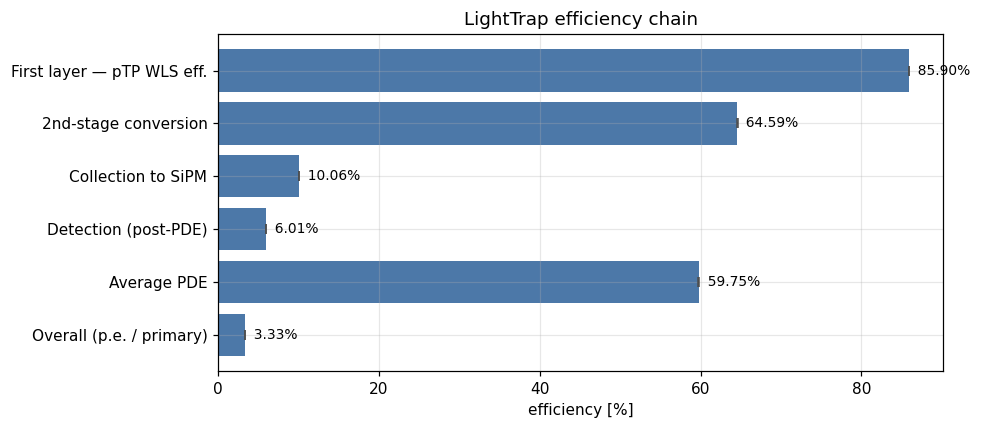

In [5]:
chain = [
    ("First layer — pTP WLS eff.",   "N_pTP / N_primary",   wilson(n_ptp,     n_primary)),
    ("2nd-stage conversion",         "N_blue / N_pTP",      wilson(n_blue,    n_ptp)),
    ("Collection to SiPM",           "N_at_sipm / N_blue",  wilson(n_at_sipm, n_blue)),
    ("Detection (post-PDE)",         "N_hits / N_blue",     wilson(n_hits,    n_blue)),
    ("Average PDE",                  "N_hits / N_at_sipm",  wilson(n_hits,    n_at_sipm)),
    ("Overall (p.e. / primary)",     "N_hits / N_primary",  wilson(n_hits,    n_primary)),
]
eff = pd.DataFrame({
    "stage":     [c[0] for c in chain],
    "ratio":     [c[1] for c in chain],
    "value [%]": [100 * c[2][0] for c in chain],
    "±1σ [%]":   [100 * c[2][1] for c in chain],
})
display(eff.style.format({"value [%]": "{:.3f}", "±1σ [%]": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([c[0] for c in chain], [100 * c[2][0] for c in chain],
        xerr=[100 * c[2][1] for c in chain], color="#4C78A8", ecolor="0.3", capsize=3)
ax.set_xlabel("efficiency [%]"); ax.set_title("LightTrap efficiency chain")
ax.invert_yaxis()
for i, c in enumerate(chain):
    ax.text(100 * c[2][0], i, f"  {100*c[2][0]:.2f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Wavelength spectra per stage

The re-emission cascade: incident primary → pTP re-emission → blue-WLS re-emission →
spectrum arriving at the SiPMs. Each successive stage should shift redward. Histograms
are booked lazily and filled in shared event loops with `RunGraphs`.

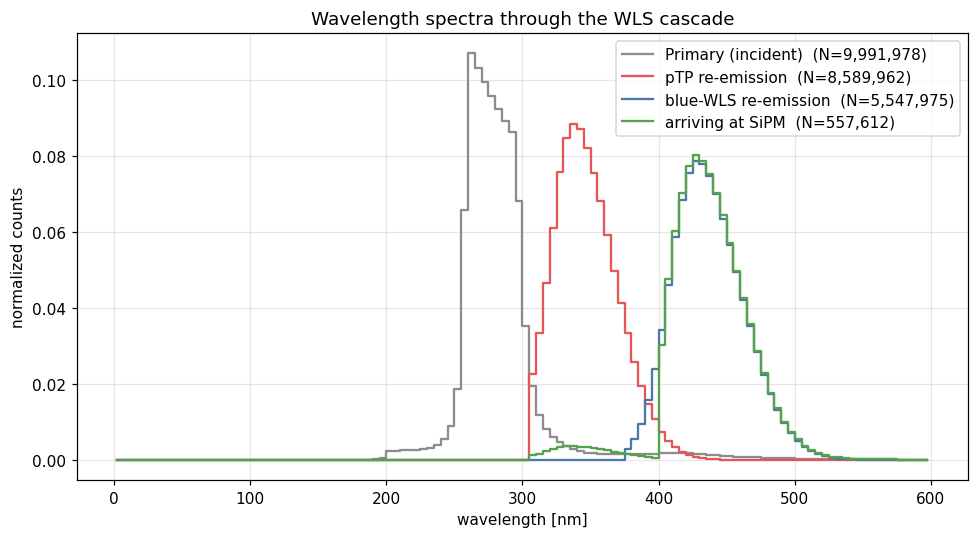

In [6]:
WL = ("h", "", 120, 0.0, 600.0)   # nm
h_prim = rdf["Primary"].Histo1D(WL, "wl")
h_ptp  = wls.Filter(f"matName=={MAT_PTP}").Histo1D(WL, "wl")
h_blue = wls.Filter(f"matName=={MAT_BLUEWLS}").Histo1D(WL, "wl")
h_sipm = rdf["SiPMPhotons"].Histo1D(("h", "", 120, 0.0, 600.0), "fwl")
ROOT.RDF.RunGraphs([h_prim, h_ptp, h_blue, h_sipm])

fig, ax = plt.subplots()
for h, label, color in [(h_prim, "Primary (incident)", "#8C8C8C"),
                        (h_ptp,  "pTP re-emission",     "#E45756"),
                        (h_blue, "blue-WLS re-emission", "#4C78A8"),
                        (h_sipm, "arriving at SiPM",    "#54A24B")]:
    cx, y, _ = th1_arrays(h)
    norm = y.sum() or 1.0
    ax.step(cx, y / norm, where="mid", label=f"{label}  (N={int(y.sum()):,})", color=color)
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel("normalized counts")
ax.set_title("Wavelength spectra through the WLS cascade"); ax.legend()
plt.tight_layout(); plt.show()

## 4. SiPM spatial hit maps

The module is 150 mm square (x, y ∈ ±75 mm); SiPMs sit flush to the **±y edges** of
the blue slab. The (x, y) maps should show two horizontal bands at y ≈ ±75 mm.
Comparing pre-PDE (`SiPMPhotons`) with post-PDE (`SiPMHits`) shows the detection
thinning. 1-D profiles show where along each axis the light lands.

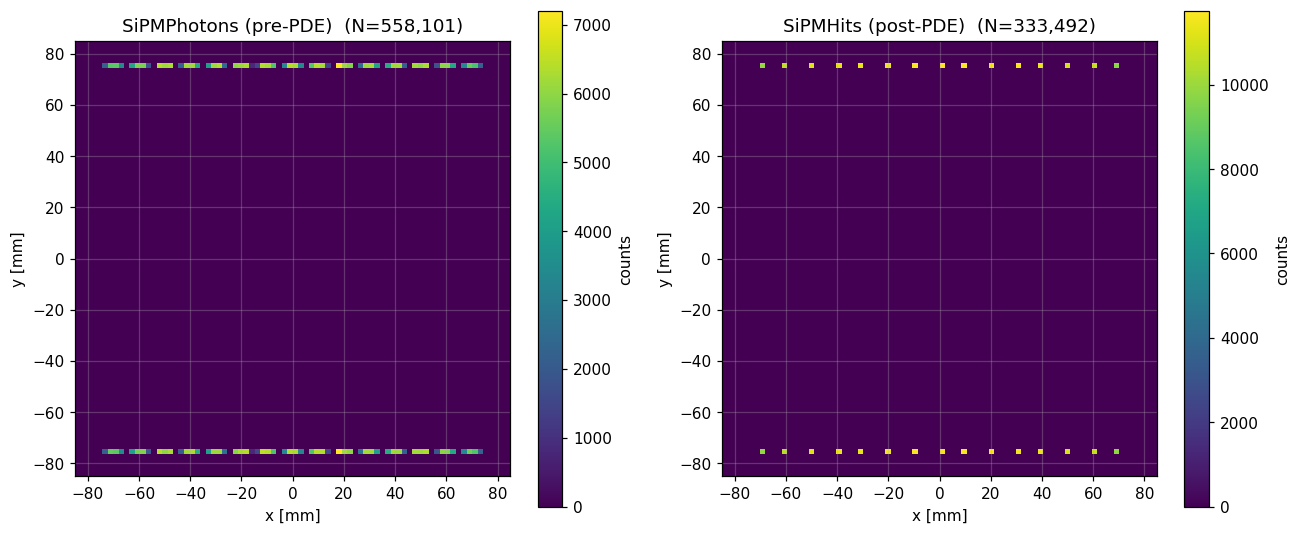

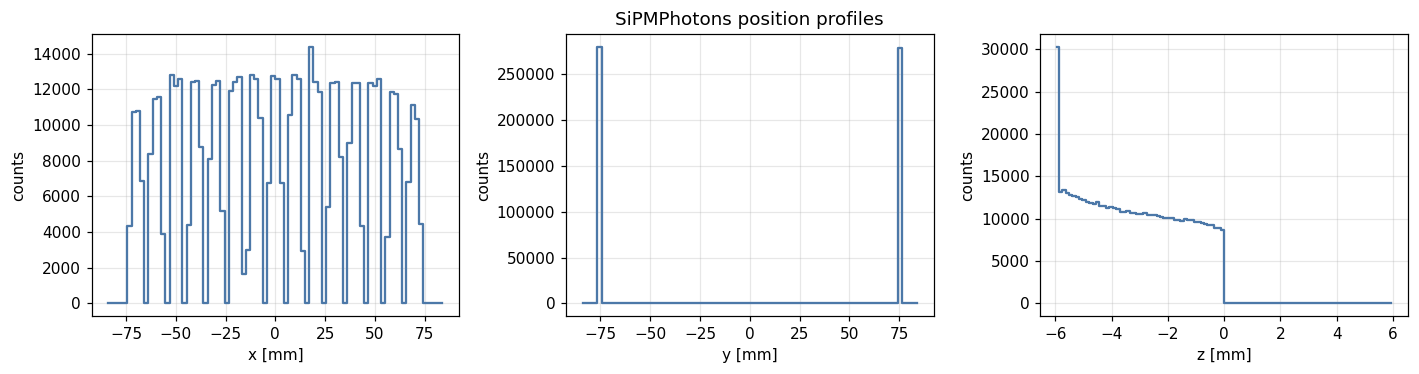

In [7]:
XY = ("h", "", 80, -85.0, 85.0, 80, -85.0, 85.0)   # mm × mm
h2_ph  = rdf["SiPMPhotons"].Histo2D(XY, "fX", "fY")
h2_hit = rdf["SiPMHits"].Histo2D(XY, "fX", "fY")
hx     = rdf["SiPMPhotons"].Histo1D(("h", "", 80, -85.0, 85.0), "fX")
hy     = rdf["SiPMPhotons"].Histo1D(("h", "", 80, -85.0, 85.0), "fY")
hz     = rdf["SiPMPhotons"].Histo1D(("h", "", 100, 0.0, 0.0),   "fZ")   # z auto-range
ROOT.RDF.RunGraphs([h2_ph, h2_hit, hx, hy, hz])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, h, title in [(axes[0], h2_ph, "SiPMPhotons (pre-PDE)"),
                     (axes[1], h2_hit, "SiPMHits (post-PDE)")]:
    Z, xe, ye = th2_array(h)
    pcm = ax.pcolormesh(xe, ye, Z, cmap="viridis")
    fig.colorbar(pcm, ax=ax, label="counts")
    ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
    ax.set_title(f"{title}  (N={int(Z.sum()):,})"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, h, xlabel in [(axes[0], hx, "x [mm]"), (axes[1], hy, "y [mm]"),
                     (axes[2], hz, "z [mm]")]:
    cx, y, _ = th1_arrays(h)
    ax.step(cx, y, where="mid", color="#4C78A8")
    ax.set_xlabel(xlabel); ax.set_ylabel("counts")
axes[1].set_title("SiPMPhotons position profiles")
plt.tight_layout(); plt.show()

## 5. Angular & timing distributions

- **Emission isotropy** — `cosTheta` and `phi` of WLS births should be flat
  (isotropic re-emission), shown separately for pTP and blue emitters.
- **Arrival timing** — `fT` of photons reaching the SiPMs (transport + TIR path
  length spread).

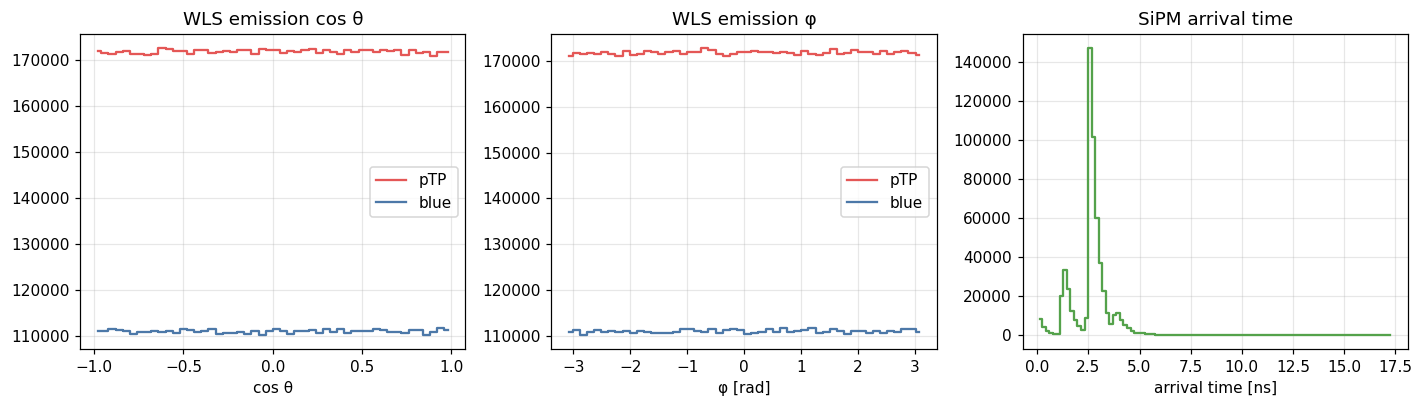

In [8]:
COS = ("h", "", 50, -1.0, 1.0)
PHI = ("h", "", 50, -math.pi, math.pi)
hc_ptp  = wls.Filter(f"matName=={MAT_PTP}").Histo1D(COS, "cosTheta")
hc_blue = wls.Filter(f"matName=={MAT_BLUEWLS}").Histo1D(COS, "cosTheta")
hp_ptp  = wls.Filter(f"matName=={MAT_PTP}").Histo1D(PHI, "phi")
hp_blue = wls.Filter(f"matName=={MAT_BLUEWLS}").Histo1D(PHI, "phi")
ht_sipm = rdf["SiPMPhotons"].Histo1D(("h", "", 100, 0.0, 0.0), "fT")   # auto-range
ROOT.RDF.RunGraphs([hc_ptp, hc_blue, hp_ptp, hp_blue, ht_sipm])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for h, lab, col in [(hc_ptp, "pTP", "#E45756"), (hc_blue, "blue", "#4C78A8")]:
    cx, y, _ = th1_arrays(h); axes[0].step(cx, y, where="mid", label=lab, color=col)
axes[0].set_xlabel("cos θ"); axes[0].set_title("WLS emission cos θ"); axes[0].legend()
for h, lab, col in [(hp_ptp, "pTP", "#E45756"), (hp_blue, "blue", "#4C78A8")]:
    cx, y, _ = th1_arrays(h); axes[1].step(cx, y, where="mid", label=lab, color=col)
axes[1].set_xlabel("φ [rad]"); axes[1].set_title("WLS emission φ"); axes[1].legend()
cx, y, _ = th1_arrays(ht_sipm)
axes[2].step(cx, y, where="mid", color="#54A24B")
axes[2].set_xlabel("arrival time [ns]"); axes[2].set_title("SiPM arrival time")
plt.tight_layout(); plt.show()

## 6. Per-region leak accounting

Where do first-layer photons go? The leak counters (trees 6/7/8) carry a `forward`
flag (1 if mom.z()>0, i.e. travelling out of layer 1 toward the blue slab). Comparing
these against the pTP births and the eventual blue births / SiPM hits shows the fate
budget and how much light is lost laterally or through the backplane.

,region,total,forward (+z),backward (-z)
0,FirstLayerBackplane,11349402,6296767,5052635
1,FirstLayerEdges,270003,138653,131350
2,SecondLayerBackplane,433,6,427


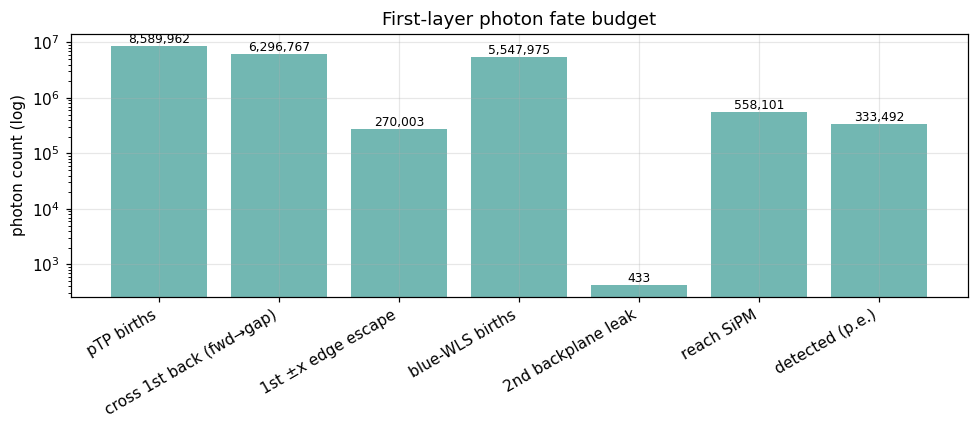

In [9]:
def fwd_split(tree):
    r = rdf[tree]
    return r.Filter("forward==1").Count(), r.Filter("forward==0").Count()

pending = {}
for t in ["FirstLayerBackplane", "FirstLayerEdges", "SecondLayerBackplane"]:
    pending[t] = fwd_split(t)
ROOT.RDF.RunGraphs([c for pair in pending.values() for c in pair])

leak = pd.DataFrame([
    {"region": t, "total": N[t],
     "forward (+z)": int(pending[t][0].GetValue()),
     "backward (-z)": int(pending[t][1].GetValue())}
    for t in pending
])
display(leak)

# First-layer photon fate budget (relative to pTP births)
fb_fwd = int(pending["FirstLayerBackplane"][0].GetValue())
fe_tot = N["FirstLayerEdges"]
sb_tot = N["SecondLayerBackplane"]
fates = {
    "pTP births":               n_ptp,
    "cross 1st back (fwd→gap)":  fb_fwd,
    "1st ±x edge escape":        fe_tot,
    "blue-WLS births":           n_blue,
    "2nd backplane leak":        sb_tot,
    "reach SiPM":                n_at_sipm,
    "detected (p.e.)":           n_hits,
}
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(fates)), list(fates.values()), color="#72B7B2")
ax.set_xticks(range(len(fates))); ax.set_xticklabels(list(fates), rotation=30, ha="right")
ax.set_yscale("log"); ax.set_ylabel("photon count (log)")
ax.set_title("First-layer photon fate budget")
for i, v in enumerate(fates.values()):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

### Optical validation (tree 5)

If populated, `OpticalValidation` records reflected/transmitted primaries vs incident
angle — a Fresnel sanity check on the first surface.

OpticalValidation: N=10,000,000  reflected=453,052 (4.53%)  transmitted=9,546,948


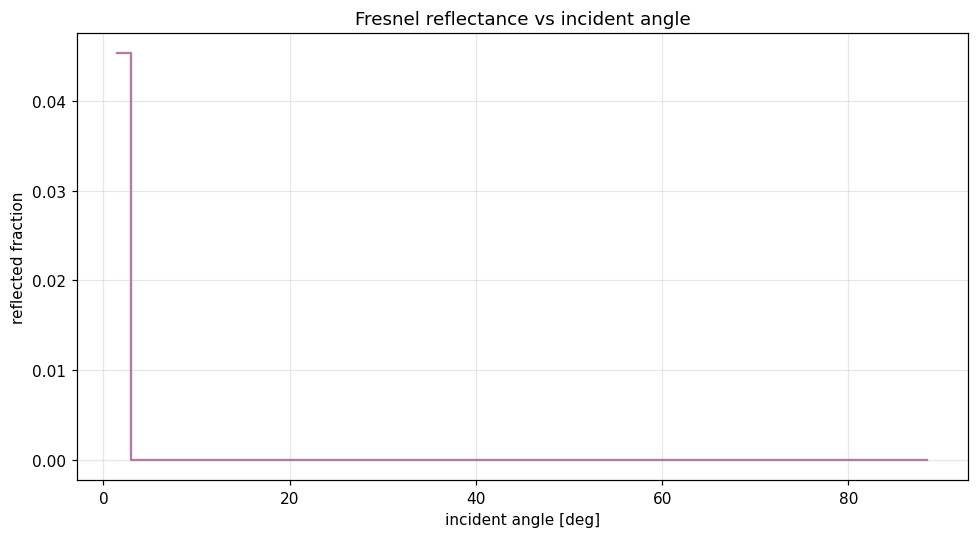

In [10]:
ov = rdf["OpticalValidation"]
n_ov = N["OpticalValidation"]
if n_ov:
    n_refl = int(ov.Filter("reflected==1").Count().GetValue())
    print(f"OpticalValidation: N={n_ov:,}  reflected={n_refl:,} "
          f"({100*n_refl/n_ov:.2f}%)  transmitted={n_ov-n_refl:,}")
    hang = ov.Histo2D(("h", "", 30, 0.0, 90.0, 2, -0.5, 1.5), "incidentAngle", "reflected")  # deg
    hang = hang.GetValue()
    Z, xe, ye = th2_array(hang)
    frac = Z[1] / np.clip(Z.sum(axis=0), 1, None)   # reflected fraction per angle bin
    cx = 0.5 * (xe[:-1] + xe[1:])
    fig, ax = plt.subplots()
    ax.step(cx, frac, where="mid", color="#B279A2")
    ax.set_xlabel("incident angle [deg]"); ax.set_ylabel("reflected fraction")
    ax.set_title("Fresnel reflectance vs incident angle"); plt.tight_layout(); plt.show()
else:
    print("OpticalValidation tree is empty for this run — skipping.")

## 7. Summary & conclusions

Consolidated key fractions for this run. `analyze_efficiency.py` on the same file
must reproduce the counts and percentages below exactly (cross-check in the
verification step).

In [11]:
summary = pd.DataFrame({
    "quantity": [
        "primary photons", "pTP WLS births", "blue-WLS births",
        "photons at SiPM", "detected p.e.",
        "eps_WLS1 (pTP/primary)", "collection (SiPM/blue)",
        "detection (hits/blue)", "avg PDE (hits/SiPM)", "overall (hits/primary)",
    ],
    "value": [
        f"{n_primary:,}", f"{n_ptp:,}", f"{n_blue:,}",
        f"{n_at_sipm:,}", f"{n_hits:,}",
        pct(*wilson(n_ptp, n_primary)), pct(*wilson(n_at_sipm, n_blue)),
        pct(*wilson(n_hits, n_blue)), pct(*wilson(n_hits, n_at_sipm)),
        pct(*wilson(n_hits, n_primary)),
    ],
})
display(summary)
print("File:", ROOT_FILE)

,quantity,value
0,primary photons,"10,000,000"
1,pTP WLS births,"8,589,962"
2,blue-WLS births,"5,547,975"
3,photons at SiPM,"558,101"
4,detected p.e.,"333,492"
5,eps_WLS1 (pTP/primary),85.900% ± 0.011%
6,collection (SiPM/blue),10.060% ± 0.013%
7,detection (hits/blue),6.011% ± 0.010%
8,avg PDE (hits/SiPM),59.755% ± 0.066%
9,overall (hits/primary),3.335% ± 0.006%


File: ../build/output_apexltsim0.root


**How to read it:** `eps_WLS1` is the pTP capture-and-reemit efficiency for the
incident spectrum; the overall figure is detected photoelectrons per incident primary
— the end-to-end light-trap yield. Compare runs by re-pointing `ROOT_FILE` and
re-running, or diff against `analysis/compare_runs.py`.